In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [37]:
from sklearn.model_selection import cross_val_score

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn import metrics

from sklearn.ensemble import BaggingClassifier


In [3]:
file = pd.ExcelFile('/Users/courtneystenstrom/Code/Capstone/Excel Files/selected.xlsx')
df = pd.read_excel(file, 'Sheet1')

## Define Functions

In [4]:
def plot_confusion(y_test, y_pred):
    sns.set(color_codes=True)
    plt.figure(1, figsize=(9,6))
    
    sns.set(font_scale=1.4)
    data = confusion_matrix(y_test, y_pred)
    df_cm = pd.DataFrame(data, columns=np.unique(y_test), index=np.unique(y_test))
    df_cm.index.name = 'Actual'
    df_cm.columns.name = 'Predicted'
    
    sns.heatmap(df_cm, annot=True, cmap='Blues', fmt='d')
    
    return

In [5]:
def auc_chart(X_test, y_test, model):
    
    y_pred_proba = model.predict_proba(X_test)[::,1]
    fpr, tpr, _ = metrics.roc_curve(y_test, y_pred_proba, pos_label=1)
    auc = metrics.roc_auc_score(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label='data 1, auc=' + str(auc))
    plt.legend(loc=4)
    plt.show()
    
    return

In [6]:
import math

def phi_stat(d,c,b,a):
    top = (d*a)-(b*c)
    bottom = math.sqrt((d+b)*(d+c)*(a+b)*(a+c))
    p = top / bottom
    
    print(p)
    return

## Models

In [7]:
model_DT = DecisionTreeClassifier()
model_RF= RandomForestClassifier()
model_LG = LogisticRegression()

### Splitting Data

In [8]:
from sklearn.model_selection import train_test_split

y = df['attempt_suicide']
X = df.drop(['attempt_suicide'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=5, test_size=0.25)

In [9]:
X

,gender,sexuality,income,race,bodyweight,social_fear,depressed,employment,education,total_improves,friend_bin,open_to_help,age_bin
0,1,2,0,5,0,1,1,1,1,1,1,1,0
1,1,2,0,4,1,1,0,1,5,2,2,1,1
2,0,2,0,0,1,1,1,5,3,1,0,1,1
3,0,2,0,5,0,1,1,5,4,0,2,0,1
4,0,2,3,5,1,1,1,2,3,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
625,1,2,2,5,2,1,1,1,3,1,1,1,0
626,1,2,4,5,2,0,0,2,3,2,1,0,1
627,1,2,2,5,1,1,1,2,1,1,0,1,1
628,1,2,0,5,2,1,0,5,0,1,0,1,1


### Scoring Models

In [10]:
from sklearn.model_selection import cross_val_score, RepeatedKFold, KFold


def get_scores(model, X, y):
    
    p = cross_val_score(model, X, y, cv=3, scoring='precision')
    print(p)
    print('Average Precision Score: ' + str(p.mean()))
    print()
    
    r = cross_val_score(model, X, y, cv=3, scoring='recall')
    print(r)
    print('Average Recall Score: ' + str(r.mean()))
    print()
    
    f = cross_val_score(model, X, y, cv=3, scoring='f1')
    print(f)
    print('Average F1 Score: ' + str(f.mean()))
    
    
    return

#### Decision Tree Classifier

In [11]:
get_scores(model_DT, X, y)

[0.625      0.65853659 0.74285714]
Average Precision Score: 0.6754645760743322

[0.72463768 0.86956522 0.76811594]
Average Recall Score: 0.78743961352657

[0.67586207 0.73684211 0.72857143]
Average F1 Score: 0.7137585342667011


#### Random Forest Classifier

In [12]:
rf_df = get_scores(model_RF, X, y)

[0.75       0.74242424 0.7704918 ]
Average Precision Score: 0.7543053485676436

[0.71014493 0.71014493 0.68115942]
Average Recall Score: 0.7004830917874396

[0.71014493 0.71212121 0.75968992]
Average F1 Score: 0.7273186873793547


#### Logistic Regression

In [13]:
lg_df = get_scores(model_LG, X, y)

[0.53968254 0.55128205 0.68518519]
Average Precision Score: 0.5920499253832587

[0.49275362 0.62318841 0.53623188]
Average Recall Score: 0.5507246376811595

[0.51515152 0.58503401 0.60162602]
Average F1 Score: 0.5672705150057067


### Comparing Models 

In [14]:
from mlxtend.evaluate import paired_ttest_5x2cv

def pairTest(A, B, X, y, score):
    t, p = paired_ttest_5x2cv(estimator1=A, estimator2=B, X=X, y=y, scoring=score, random_seed=1)

    print('P-value: %.3f, t-Statistic: %.3f' % (p, t))
# interpret the result
    if p <= 0.05:
        print('Difference between mean performance is real')
    else:
        print('Algorithms probably have the same performance')

## Model Training

In [15]:
model_A = DecisionTreeClassifier()
model_B = RandomForestClassifier(n_estimators=300)
model_C = LogisticRegression(solver='lbfgs')

In [16]:
model_A.fit(X_train, y_train)
model_B.fit(X_train, y_train)
model_C.fit(X_train, y_train)

LogisticRegression()

In [17]:
y_pred_A = model_A.predict(X_test)
y_pred_B = model_B.predict(X_test)
y_pred_C = model_C.predict(X_test)

In [38]:
bag = BaggingClassifier()
bag.fit(X_train, y_train)
bag_pred =bag.predict(X_test)

In [40]:
print(classification_report(y_test, bag_pred))

              precision    recall  f1-score   support

           0       0.92      0.88      0.90       113
           1       0.72      0.80      0.76        45

    accuracy                           0.85       158
   macro avg       0.82      0.84      0.83       158
weighted avg       0.86      0.85      0.86       158



### Recall Scores

In [18]:
pairTest(model_A, model_B, X, y, 'recall')

P-value: 0.425, t-Statistic: 0.868
Algorithms probably have the same performance


In [19]:
pairTest(model_A, model_C, X, y, 'recall')

P-value: 0.035, t-Statistic: 2.863
Difference between mean performance is real


In [20]:
pairTest(model_B, model_C, X, y, 'recall')

P-value: 0.016, t-Statistic: 3.567
Difference between mean performance is real


### Decision Tree Classifier

In [21]:
print(classification_report(y_test, y_pred_A))

              precision    recall  f1-score   support

           0       0.89      0.81      0.85       113
           1       0.61      0.76      0.67        45

    accuracy                           0.79       158
   macro avg       0.75      0.78      0.76       158
weighted avg       0.81      0.79      0.80       158



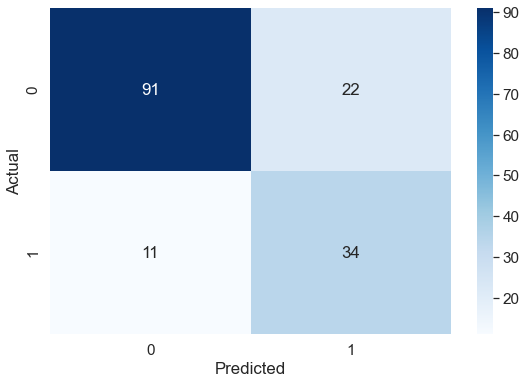

In [22]:
plot_confusion(y_test, y_pred_A)

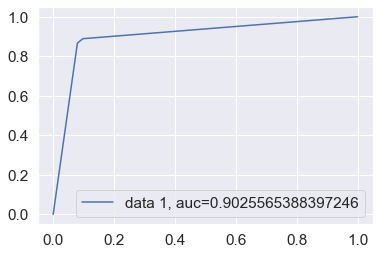

In [23]:
auc_chart(X_test, y_test, model_A)

In [24]:
phi_stat(91,17,17,33)

0.5025925925925926


### Random Forest Classifier

In [25]:
print(classification_report(y_test, y_pred_B))

              precision    recall  f1-score   support

           0       0.90      0.83      0.86       113
           1       0.64      0.76      0.69        45

    accuracy                           0.81       158
   macro avg       0.77      0.79      0.78       158
weighted avg       0.82      0.81      0.81       158



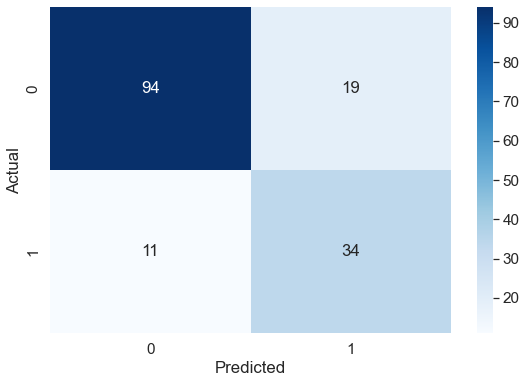

In [26]:
plot_confusion(y_test, y_pred_B)

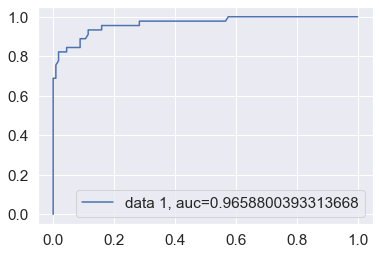

In [27]:
auc_chart(X_test, y_test, model_B)

In [28]:
phi_stat(101,7,20,30)

0.5877699998692516


### Logistic Regression

In [29]:
print(classification_report(y_test, y_pred_C))

              precision    recall  f1-score   support

           0       0.83      0.77      0.80       113
           1       0.51      0.60      0.55        45

    accuracy                           0.72       158
   macro avg       0.67      0.68      0.67       158
weighted avg       0.74      0.72      0.73       158



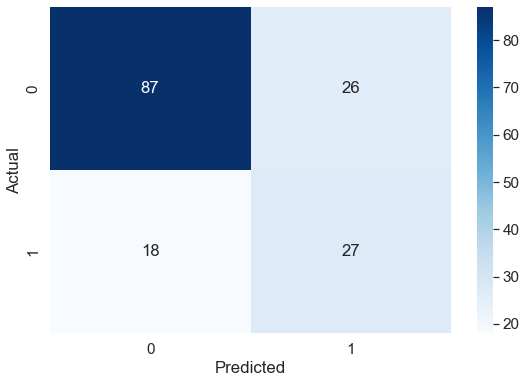

In [30]:
plot_confusion(y_test, y_pred_C)

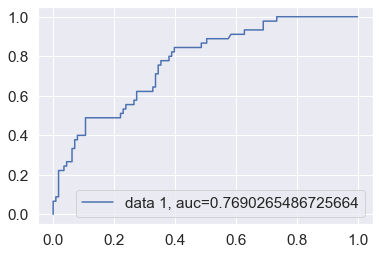

In [31]:
auc_chart(X_test, y_test, model_C)

In [32]:
phi_stat(98,10,34,16)

0.28525144119130763


## Optimization

In [ ]:
from sklearn.model_selection import GridSearchCV

forest_params = [{'max_depth': list(range(10, 15)), 'max_features': list(range(0,14))}]

param_grid = {
    'n_estimators' : [200, 500],
    'max_features' : ['auto', 'sqrt', 'log2'],
    'max_depth' : list(range(10,18)),
    'criterion' : ['gini', 'entropy'],
}

GS = GridSearchCV(model_B, param_grid=param_grid, scoring='recall', cv=5)

GS.fit(X, y)

In [ ]:
GS.best_params_

In [ ]:
GS.best_score_

## Other Information

In [ ]:
sort = model_B.feature_importances_.argsort()

plt.barh(df.columns[sort], model_B.feature_importances_[sort])
plt.xlabel("Feature Importances")

In [ ]:
feat_df = pd.DataFrame(model_B.feature_importances_[sort], df.columns[sort])
feat_df = feat_df.reset_index()
feat_df.columns = ['Variable', 'Score']
feat_df.sort_values(by='Score', ascending=False)

In [ ]:
pred_prob1 = model_A.predict_proba(X_test)
pred_prob2 = model_B.predict_proba(X_test)
pred_prob3 = model_C.predict_proba(X_test)

fpr1, tpr1, thresh1 = roc_curve(y_test, pred_prob1[:,1], pos_label=1)
fpr2, tpr2, thresh2 = roc_curve(y_test, pred_prob2[:,1], pos_label=1)
fpr3, tpr3, thresh3 = roc_curve(y_test, pred_prob3[:,1], pos_label=1)

# roc curve for tpr = fpr 
random_probs = [0 for i in range(len(y_test))]
p_fpr, p_tpr, _ = roc_curve(y_test, random_probs, pos_label=1)


from sklearn.metrics import roc_auc_score

# auc scores
auc_score1 = roc_auc_score(y_test, pred_prob1[:,1])
auc_score2 = roc_auc_score(y_test, pred_prob2[:,1])
auc_score3 = roc_auc_score(y_test, pred_prob3[:,1])

print(auc_score1, auc_score2, auc_score3)

In [ ]:
plt.style.use('seaborn')

# plot roc curves
plt.plot(fpr1, tpr1, linestyle='--',color='orange', label='Decision Tree')
plt.plot(fpr2, tpr2, linestyle='--',color='green', label='Random Forest')
plt.plot(fpr3, tpr3, linestyle='--',color='red', label='Logistic Regression')

plt.title('ROC curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')

plt.legend(loc='best')
plt.savefig('ROC',dpi=300)
plt.show();

In [ ]:
pd.DataFrame(y_pred_A).to_excel('a.xlsx')
pd.DataFrame(y_pred_B).to_excel('b.xlsx')
y_test.to_excel('test.xlsx')